### В данном уроке мы выделим еще несколько потенциально важных фичей из изначального датасета и попробуем применить изученные методы отбора признаков к итоговому датасету.

In [42]:
import numpy as np
import pandas as pd

processed_data = pd.read_csv('processed_data.csv', index_col='id')

processed_data.head()

,vendor_id,passenger_count,store_and_fwd_flag,distance_km,log_trip_duration
id,,,,,
id2875421,1,930.399753,0,1.500479,6.122493
id2377394,0,930.399753,0,1.807119,6.498282
id3858529,1,930.399753,0,6.392080,7.661527
id3504673,1,930.399753,0,1.487155,6.063785
id2181028,1,930.399753,0,1.189925,6.077642


In [43]:
initial_data = pd.read_csv('taxi_dataset.csv')

initial_data.head()

,id,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag
0,id2875421,2,2016-03-14 17:24:55,2016-03-14 17:32:30,1,-73.982155,40.767937,-73.964630,40.765602,N
1,id2377394,1,2016-06-12 00:43:35,2016-06-12 00:54:38,1,-73.980415,40.738564,-73.999481,40.731152,N
2,id3858529,2,2016-01-19 11:35:24,2016-01-19 12:10:48,1,-73.979027,40.763939,-74.005333,40.710087,N
3,id3504673,2,2016-04-06 19:32:31,2016-04-06 19:39:40,1,-74.010040,40.719971,-74.012268,40.706718,N
4,id2181028,2,2016-03-26 13:30:55,2016-03-26 13:38:10,1,-73.973053,40.793209,-73.972923,40.782520,N


In [44]:
initial_data.shape[0] == processed_data.shape[0]

True

In [45]:
### Вернем в датасет колонку pickup_datetime

initial_data = initial_data.set_index('id')

processed_data = pd.merge(processed_data, initial_data['pickup_datetime'],
                          left_index=True, right_index=True)

In [46]:
processed_data.head()

,vendor_id,passenger_count,store_and_fwd_flag,distance_km,log_trip_duration,pickup_datetime
id,,,,,,
id2875421,1,930.399753,0,1.500479,6.122493,2016-03-14 17:24:55
id2377394,0,930.399753,0,1.807119,6.498282,2016-06-12 00:43:35
id3858529,1,930.399753,0,6.392080,7.661527,2016-01-19 11:35:24
id3504673,1,930.399753,0,1.487155,6.063785,2016-04-06 19:32:31
id2181028,1,930.399753,0,1.189925,6.077642,2016-03-26 13:30:55


Напомним, **pickup_datetime** - время начала поездки.

Кажется, что в зависимости от месяца/дня недели/времени суток движение на дорогах может отличаться. Как из-за погодных условий, так и из-за загруженности транспорта. Поэтому, есть подозрение, что будет полезно выделить ряд признаков из колонки **pickup_datetime**. Давайте исследуем зависимость нашей таргетной переменной от указанных факторов.

In [47]:
processed_data['pickup_datetime'] = pd.to_datetime(processed_data['pickup_datetime'])

processed_data['date'] = processed_data.pickup_datetime.dt.date
processed_data['day_of_week'] = processed_data.pickup_datetime.dt.dayofweek
processed_data['hour'] = processed_data.pickup_datetime.dt.hour
processed_data['month'] = processed_data.pickup_datetime.dt.month

In [48]:
processed_data.head()

,vendor_id,passenger_count,store_and_fwd_flag,distance_km,log_trip_duration,pickup_datetime,date,day_of_week,hour,month
id,,,,,,,,,,
id2875421,1,930.399753,0,1.500479,6.122493,2016-03-14 17:24:55,2016-03-14,0,17,3
id2377394,0,930.399753,0,1.807119,6.498282,2016-06-12 00:43:35,2016-06-12,6,0,6
id3858529,1,930.399753,0,6.392080,7.661527,2016-01-19 11:35:24,2016-01-19,1,11,1
id3504673,1,930.399753,0,1.487155,6.063785,2016-04-06 19:32:31,2016-04-06,2,19,4
id2181028,1,930.399753,0,1.189925,6.077642,2016-03-26 13:30:55,2016-03-26,5,13,3


Исследуем, когда и сколько поездок было совершено. 

Начнем с графиков, показывающих количество поездок в зависимости от времени суток/даты и т.д.

Так же полезно сразу показать и среднее значение таргетной переменной.

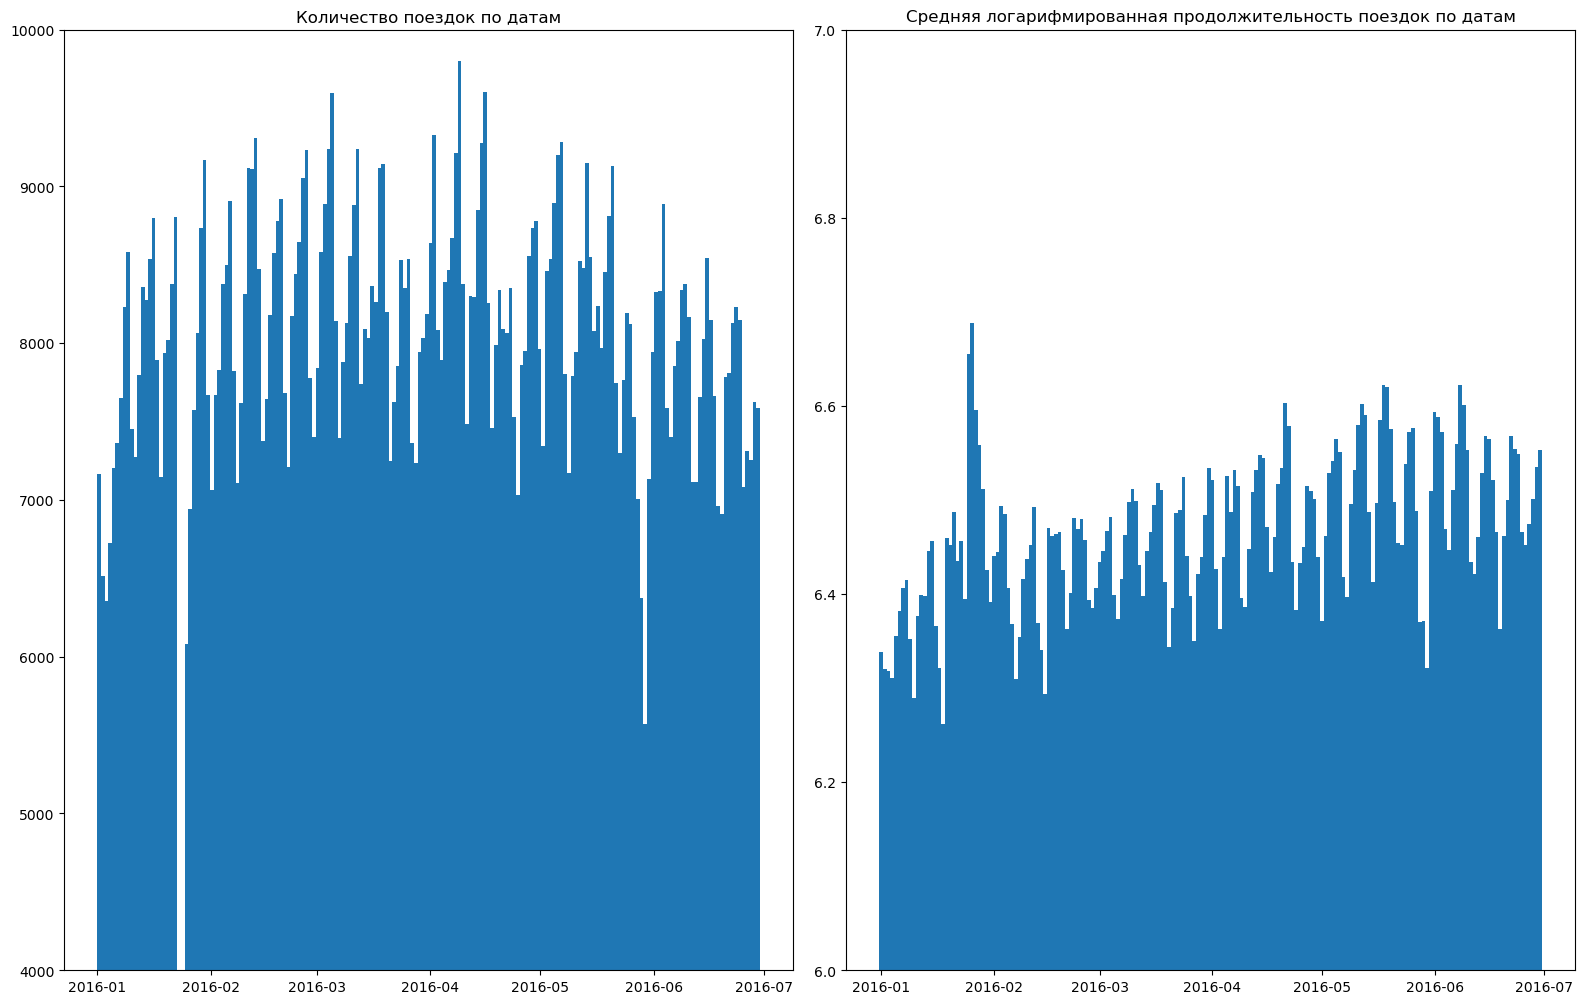

In [40]:
import matplotlib.pyplot as plt

fig = plt.figure()

fig.set_size_inches(16, 10)

ax_1 = fig.add_subplot(1, 2, 1)
plt.hist(processed_data['date'], bins=processed_data.date.unique().shape[0])
plt.ylim((4000, 10000))

ax_2 = fig.add_subplot(1, 2, 2)
plt.bar(sorted(list(processed_data['date'].unique())), 
        processed_data.groupby('date', as_index=False)['log_trip_duration'].mean()['log_trip_duration'],
        width=1)
plt.ylim((6, 7))

fig.tight_layout()

ax_1.set(title = 'Количество поездок по датам')
ax_2.set(title = 'Средняя логарифмированная продолжительность поездок по датам')

plt.show()

Кажется, что внутри недели есть некоторая зависимость таргета от дня недели. 

Такая же зависимость может оказаться и внутри дня (в завимости от часов).

Предлагаю исследовать эту зависимость подробнее.

Изобразите следующие графики зависимостей:

- Количество поездок/Средняя продолжительность поездки vs День недели
- Количество поездок/Средняя продолжительность поездки vs время суток
- Средняя продолжительность поездки vs время суток для каждого дня недели (например, нарисовав с разными цветами и, соответственно, легендами)
- Аналогичные графики, используя информацию о месяце, внутри которого была совершена поездка.
- Ящики с усами для различных: времени суток, дня недели, месяца

Используйте любые доступные инструменты pyplot!

Далее, на основе полученных результатов, мы будем принимать решение о создании новых признаков.

EDA можно использовать не только для того, чтобы понять, какие фичи можно убрать из датасета. Но и для выделения базовых признаков. Этим и займемся!

P.S. Сами графики мы проверять у Вас не будем. Зато для ответа на устные вопросы понадобятся, поэтому, в любом случае, крайне рекомендуем поупражняться. Поэтому рисовать все графики не обязательно - ограничьтесь теми, которые помогут Вам ответить на тестовые вопросы.

**Hint**: обратите внимание на сильную просадку в январе. Почему она могла произойти - можно прочитать <a href="https://en.wikipedia.org/wiki/January_2016_United_States_blizzard"> здесь</a>. В будущем можно будет создать бинарный признак "произошла ли поездка во время сильного снегопада".


Text(0.5, 1.0, 'Средняя продолжительность по дням недели')

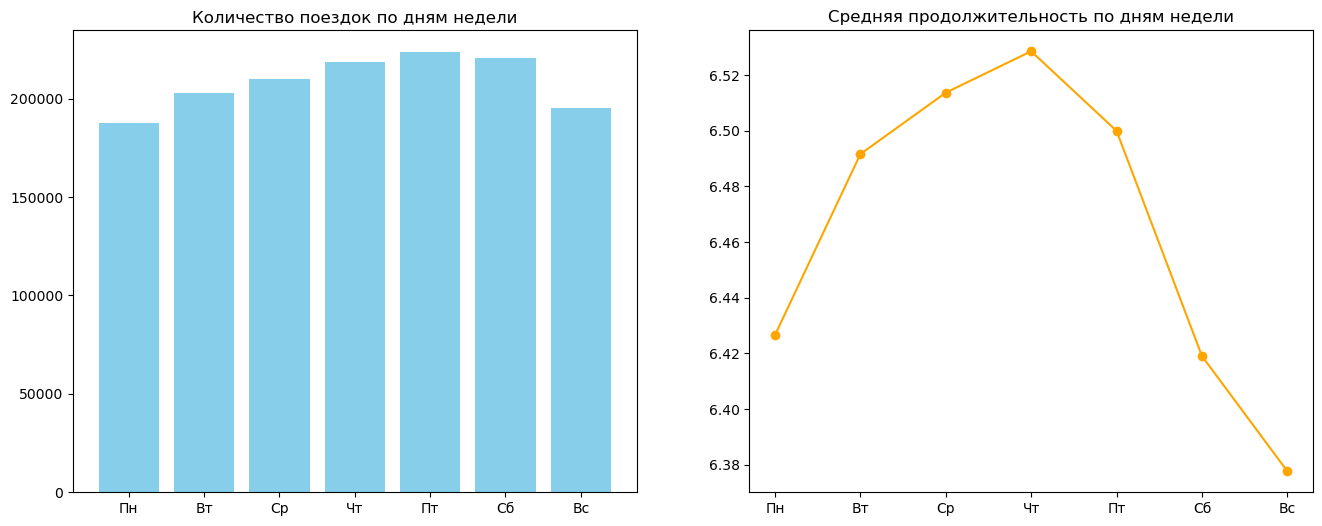

In [41]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd


# 1. Количество поездок и средняя продолжительность по дням недели
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
weekday_counts = processed_data.groupby('day_of_week').size()
weekday_avg = processed_data.groupby('day_of_week')['log_trip_duration'].mean()

ax1.bar(weekday_counts.index, weekday_counts, color='skyblue')
ax1.set_xticks(range(7))
ax1.set_xticklabels(['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс'])
ax1.set_title('Количество поездок по дням недели')

ax2.plot(weekday_avg.index, weekday_avg, marker='o', color='orange')
ax2.set_xticks(range(7))
ax2.set_xticklabels(['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс'])
ax2.set_title('Средняя продолжительность по дням недели')

Text(0.5, 1.0, 'Средняя продолжительность по времени суток')

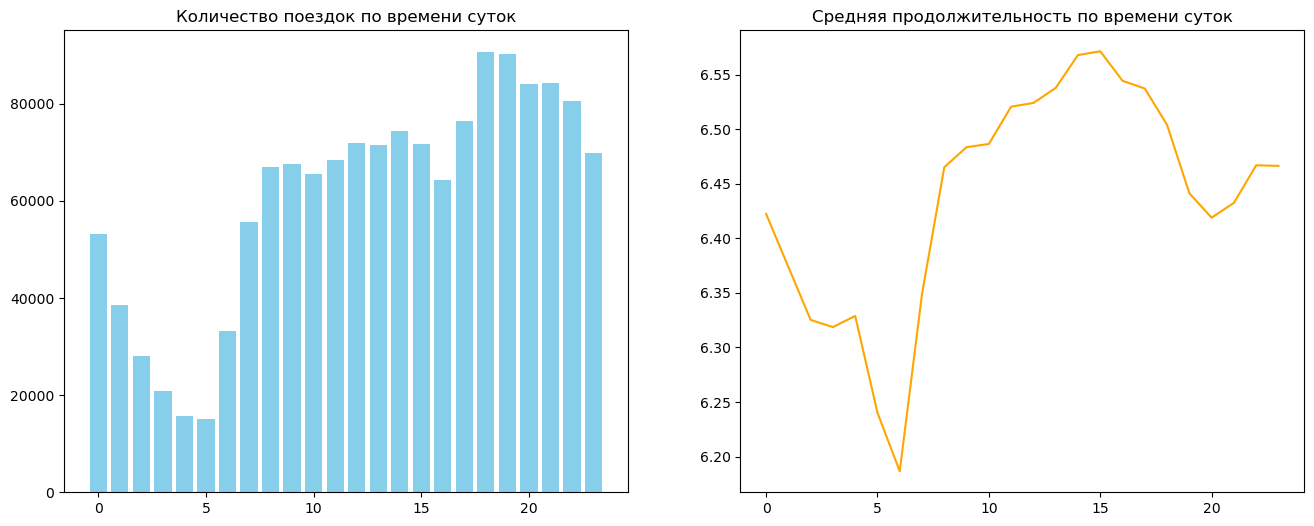

In [42]:
# 2. Количество поездок и средняя продолжительность по времени суток
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
hour_counts = processed_data.groupby('hour').size()
hour_avg = processed_data.groupby('hour')['log_trip_duration'].mean()

ax1.bar(hour_counts.index, hour_counts, color='skyblue')
ax1.set_title('Количество поездок по времени суток')

ax2.plot(hour_avg.index, hour_avg, color='orange')
ax2.set_title('Средняя продолжительность по времени суток')

Кажется, что полученные выводы из графиков выше достаточны для того, чтобы посчитать признаки, связанные с временем/датой поездки, достаточно важными. На их основе выделим еще пару.

Добавьте следующие бинарные признаки:


1. Была ли в день поездки буря (основываясь на единственном обнаруженном таком дне)
2. Является ли время поездки статистически самым проблемным, то есть час пиком?

Для создания 2ой фичи используйте следующую логику: посчитаем для каждой пары "день недели"-"время суток" среднее значение таргета. Найдем топ-10 самых "больших" пар. Если поездка была совершена во входящее в этот топ время, то ставим 1. Иначе - 0. Получается бинарный признак.

P.S. назовите колонки **anomaly** и **traffic_jam**

In [84]:
processed_data['id']

KeyError: 'id'

In [49]:
### Создадим первый бинарный признак
### Your code is here
# 1. Преобразуем колонку date в datetime
processed_data['date'] = pd.to_datetime(processed_data['date'])

# 2. Создаем признак anomaly (снежная буря в январе 2016)
processed_data['anomaly'] = (
    (processed_data['date'].dt.year == 2016) & 
    (processed_data['date'].dt.month == 1) & 
    (processed_data['date'].dt.day.isin([22, 23, 24]))
).astype(int)

In [50]:
# 1. Группируем данные и находим топ-10 слотов
top_slots = (
    processed_data.groupby(['day_of_week', 'hour'])['log_trip_duration']
    .mean()
    .nlargest(10)
    .index.tolist()  # Получаем список кортежей (day_of_week, hour)
)

# 2. Создаем бинарный признак через проверку вхождения
processed_data['traffic_jam'] = (
    processed_data[['day_of_week', 'hour']]
    .apply(lambda row: 1 if (row['day_of_week'], row['hour']) in top_slots else 0, axis=1)
    .astype(int)
)

# 3. Проверяем колонки
print("Колонки после преобразования:", processed_data.columns.tolist())

Колонки после преобразования: ['vendor_id', 'passenger_count', 'store_and_fwd_flag', 'distance_km', 'log_trip_duration', 'pickup_datetime', 'date', 'day_of_week', 'hour', 'month', 'anomaly', 'traffic_jam']


In [21]:
# 1. Сбрасываем индекс в колонку
processed_data = processed_data.reset_index()

# 2. Меняем тип колонки 'id' на строку
processed_data['id'] = processed_data['id'].astype(str)

# 3. Возвращаем 'id' обратно в индекс (если нужно)
processed_data = processed_data.set_index('id')

In [51]:
processed_data.index = processed_data.index.astype("str")
processed_data.head()

,vendor_id,passenger_count,store_and_fwd_flag,distance_km,log_trip_duration,pickup_datetime,date,day_of_week,hour,month,anomaly,traffic_jam
id,,,,,,,,,,,,
id2875421,1,930.399753,0,1.500479,6.122493,2016-03-14 17:24:55,2016-03-14,0,17,3,0,0
id2377394,0,930.399753,0,1.807119,6.498282,2016-06-12 00:43:35,2016-06-12,6,0,6,0,0
id3858529,1,930.399753,0,6.392080,7.661527,2016-01-19 11:35:24,2016-01-19,1,11,1,0,1
id3504673,1,930.399753,0,1.487155,6.063785,2016-04-06 19:32:31,2016-04-06,2,19,4,0,0
id2181028,1,930.399753,0,1.189925,6.077642,2016-03-26 13:30:55,2016-03-26,5,13,3,0,0


Теперь колонки **pickup_datetime**, **date** можно убрать. А про оставшиеся **day_of_week**, **hour**, **month** необходимо подумать:

- С одной стороны, первые две можно убрать, так как на их основе была создана колонка **traffic_jam**
- С другой стороны, зависимость с колонкой **traffic_jam** нелинейная, поэтому можно попробовать использовать все фичи в комбинации. Конечно, лучше попробовать оба варианта и проэкспериментировать, но ради упрощения - оставим все колонки. Хоть **day_of_week**, **hour** и описываются числами, мы понимаем, что это скорее категориальные фичи. Потому что, например, отношение между 23:00 и 00:00 не такое же, как между числами 23 и 0. Закодируем их с помощью OneHotEncoder. 
- Последняя (**month**) очевидно категориальная. Можно закодировать ее тоже через OneHotEncoder.

In [ ]:
processed_data = processed_data.drop(['pickup_datetime', 'date'], axis=1)

In [52]:
# Предположим, что исходные данные уже загружены в DataFrame processed_data

# Удаление ненужных колонок (если они существуют)
processed_data = processed_data.drop(['pickup_datetime', 'date'], axis=1, errors='ignore')

# One-Hot Encoding для категориальных признаков
for col in ['day_of_week', 'hour', 'month']:
    dummies = pd.get_dummies(processed_data[col], prefix=col, drop_first=True)
    processed_data = pd.concat([processed_data.drop(col, axis=1), dummies], axis=1)

# Приведение типов
if 'id' in processed_data.columns:
    processed_data['id'] = processed_data['id'].astype(str)
    
processed_data = processed_data.astype(
    {col: 'int' for col in processed_data.columns if col not in ['passenger_count', 'distance_km', 'log_trip_duration', 'id']}
)

print(f"Итоговое количество колонок: {len(processed_data.columns)}")

Итоговое количество колонок: 41


In [53]:
processed_data.head(5).to_csv('output12.csv', sep=',')

Что же, мы с Вами научились с помощью EDA визуализаций понимать важность признаков не только постфактум, но и до того, как сформировался финальный датасет - на этапе **выделения базовых фичей**.

In [41]:
processed_data.dtypes


vendor_id               int64
passenger_count       float64
store_and_fwd_flag      int64
distance_km           float64
log_trip_duration     float64
anomaly                 int64
traffic_jam             int64
day_of_week_1           int64
day_of_week_2           int64
day_of_week_3           int64
day_of_week_4           int64
day_of_week_5           int64
day_of_week_6           int64
hour_1                  int64
hour_2                  int64
hour_3                  int64
hour_4                  int64
hour_5                  int64
hour_6                  int64
hour_7                  int64
hour_8                  int64
hour_9                  int64
hour_10                 int64
hour_11                 int64
hour_12                 int64
hour_13                 int64
hour_14                 int64
hour_15                 int64
hour_16                 int64
hour_17                 int64
hour_18                 int64
hour_19                 int64
hour_20                 int64
hour_21   

Обратимся теперь к методам фильтрации - например, применим корреляционный анализ для одной пары фичей, чтобы понять, нет ли относительно этих колонок в нашем датасете избытка информации. 

Вспомним так же изначальные вещественные признаки - distance_km, passenger_count

Посчитайте корреляцию между ними. Есть ли какие-то основания для беспокойства?

In [54]:
### Your code is here

# Вычисляем корреляцию Пирсона
correlation = processed_data[['distance_km', 'passenger_count']].corr().iloc[0, 1]

# Округляем до 3 знаков
rounded_corr = round(correlation, 3)

print(f"Корреляция между distance_km и passenger_count: {rounded_corr}")

Корреляция между distance_km и passenger_count: 0.017


In [ ]:
processed_data.head()

In [55]:
### На данный момент у нас 41 фича
### Представим, что хочется сократить их количество до 5.
### Воспользуемся для этим каким-нибудь методом обертки
### Например, метод прямого отбора

### Your code is here
from sklearn.linear_model import LinearRegression
from sklearn.feature_selection import SequentialFeatureSelector

# Разделяем данные на признаки и целевую переменную
X = processed_data.drop('log_trip_duration', axis=1)
y = processed_data['log_trip_duration']

# Создаем модель линейной регрессии
model = LinearRegression()

# Инициализируем селектор для выбора 5 фич
sfs = SequentialFeatureSelector(
    estimator=model,
    n_features_to_select=5,
    direction='forward',  # Прямой отбор (последовательное добавление)
    cv=5  # Кросс-валидация
)

# Обучаем селектор
sfs.fit(X, y)

# Получаем маску выбранных фич
selected_features_mask = sfs.get_support()

# Выводим названия выбранных признаков
selected_features = X.columns[selected_features_mask].tolist()
print(f"Выбранные фичи: {selected_features}")

Выбранные фичи: ['distance_km', 'traffic_jam', 'day_of_week_6', 'hour_5', 'hour_6']


In [ ]:
### Перечислите фичи, которые окажутся наиболее желанными
### Your code is here


In [57]:
### Представим, что мы с Вами ничего не знаем про Кросс-Валидацию и отложенную выборку
### Замерьте качество линейной регрессии на данных фичах
### Сильно ли оно отличается от полученного на Кросс-Валидации в прошлом уроке в ДЗ?

### Your code is here
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# Создаем и обучаем модель на всех данных (без разделения)
X_selected = processed_data[['distance_km', 'traffic_jam', 'day_of_week_6', 'hour_5', 'hour_6']]
model = LinearRegression()
model.fit(X_selected, y)
y_pred = model.predict(X_selected)

# Вычисляем MSE
mse = mean_squared_error(y, y_pred)
rounded_mse = round(mse, 3)

print(f"MSE на обучающих данных: {rounded_mse}")


MSE на обучающих данных: 0.415


In [ ]:
1